Numerical = أرقام
Categorical = فئات
Binary
Session ID — رقم الجلسة — رقم فريد لكل جلسة اتصال.
Network Packet Size — حجم حزمة الشبكة — حجم البيانات الموجودة في حزمة الشبكة.
تخيّل أن الكمبيوتر يرسل بيانات عبر الإنترنت. البيانات لا تُرسل كلها دفعة واحدة، بل يتم تقسيمها إلى حزم صغيرة (Packets).
____________________________________________________________________________________________________________
Protocol Type — نوع البروتوكول — نوع بروتوكول الاتصال مثل TCP أو UDP أو ICMP.
| Protocol | بالعربي                         | الفكرة ببساطة                                     |
| -------- | ------------------------------- | ------------------------------------------------- |
| **TCP**  | بروتوكول التحكم بالنقل          | يتأكد أن البيانات وصلت بشكل صحيح وكامل            |
| **UDP**  | بروتوكول بيانات المستخدم        | يرسل البيانات بسرعة، بدون التأكد الكامل من وصولها |
| **ICMP** | بروتوكول رسائل التحكم بالإنترنت | يستخدم غالبًا لفحص الاتصال بين الأجهزة            |
TCP = Transmission Control Protocol 
UDP = User Datagram Protocol 
ICMP = Internet Control Message Protoco
___________________________________________________________________________________________________________
Login Attempts — محاولات تسجيل الدخول — عدد محاولات تسجيل الدخول أثناء الجلسة.
Session Duration — مدة الجلسة — المدة التي استمر فيها اتصال الشبكة.
Encryption Used — التشفير المستخدم — نوع التشفير المستخدم مثل AES أو DES، وقد تكون القيمة مفقودة.
AES

AES = Advanced Encryption Standard      

يعني معيار تشفير حديث وقوي.

فكر فيه مثل 🔒 قفل قوي وحديث.

أكثر أمانًا
سريع
يُستخدم على نطاق واسع حاليًا
مناسب لحماية البيانات الحساسة
🔓 DES

DES = Data Encryption Standard

هو أيضًا طريقة لتشفير البيانات، لكنه قديم مقارنة بـ AES.

فكر فيه مثل 🔒 قفل قديم.

أضعف من AES
أصبح غير مناسب للحماية الحديثة
يمكن كسره بسهولة أكبر بسبب قِدمه
____________________________________________________________________________________________________________
IP Reputation Score — درجة سمعة عنوان IP — درجة رقمية توضح سمعة عنوان الـIP.
هي درجة رقمية تساعدنا على معرفة إذا كان عنوان الـIP يبدو موثوقًا أم مرتبطًا بنشاط مشبوه.
____________________________________________________________________________________________________________
Failed Logins — محاولات تسجيل الدخول الفاشلة — عدد محاولات تسجيل الدخول التي لم تنجح.
Browser Type — نوع المتصفح — المتصفح المستخدم مثل Chrome أو Firefox أو Edge أو Safari.
Unusual Time Access — الوصول في وقت غير معتاد — يوضح هل حدث الاتصال في وقت غير معتاد: 0 = لا، 1 = نعم.
يعني هل حدثت الـ Session في وقت يعتبر غير طبيعي أو غير معتاد بالنسبة للنظام.
___________________________________________________________________________________________________________
Attack Detected — اكتشاف هجوم — يوضح هل تم اكتشاف هجوم في الجلسة: 0 = لا يوجد هجوم، 1 = تم اكتشاف هجوم.


Session ID - رقم الجلسة - Unique number for each network session
Network Packet Size - حجم حزمة الشبكة - Size of the network packet
Protocol Type - نوع البروتوكول - TCP, UDP, or ICMP
Login Attempts - محاولات تسجيل الدخول - Number of login attempts
Session Duration - مدة الجلسة - Duration of the network session
Encryption Used - التشفير المستخدم - AES, DES, or missing value
IP Reputation Score - درجة سمعة IP - Numerical reputation score of the IP address
Failed Logins - محاولات الدخول الفاشلة - Number of failed login attempts
Browser Type - نوع المتصفح - Chrome, Firefox, Edge, Safari, or Unknown
Unusual Time Access - الوصول في وقت غير معتاد - 0 = No, 1 = Yes
Attack Detected - اكتشاف الهجوم - 0 = No attack, 1 = Attack detected

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

In [38]:
cybersecurity_intrusion_data=pd.read_csv(r'C:\Users\USER\OneDrive\Desktop\Aya\Data_Analysis\project_Data_Analysis\cybersecurity_intrusion_data\cybersecurity_intrusion_data.csv')
cybersecurity_intrusion_data

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0
...,...,...,...,...,...,...,...,...,...,...,...
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1
9533,SID_09534,380,TCP,3,182.848475,NaN,0.408485,0,Chrome,0,0
9534,SID_09535,664,TCP,5,35.170248,AES,0.359200,1,Firefox,0,0
9535,SID_09536,406,TCP,4,86.664703,AES,0.537417,1,Chrome,1,0


In [39]:
cybersecurity_intrusion_data.head(10)

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0
5,SID_00006,453,UDP,5,380.471550,AES,0.422486,2,Chrome,1,0
6,SID_00007,815,ICMP,4,728.107165,AES,0.413772,1,Chrome,0,1
7,SID_00008,653,TCP,3,12.599906,DES,0.097719,3,Chrome,1,1
8,SID_00009,406,TCP,2,542.558895,NaN,0.294580,0,Chrome,1,0
9,SID_00010,608,UDP,6,531.944107,NaN,0.424117,1,Chrome,0,0


In [40]:
cybersecurity_intrusion_data.tail(10)


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
9527,SID_09528,588,TCP,5,158.789714,AES,0.728379,0,Firefox,1,1
9528,SID_09529,535,TCP,7,50.518476,DES,0.767659,1,Edge,1,1
9529,SID_09530,469,TCP,1,2487.078455,NaN,0.497153,0,Chrome,0,0
9530,SID_09531,661,UDP,5,1037.597568,NaN,0.613622,3,Chrome,0,1
9531,SID_09532,746,TCP,7,315.151758,DES,0.190059,3,Chrome,0,1
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1
9533,SID_09534,380,TCP,3,182.848475,NaN,0.408485,0,Chrome,0,0
9534,SID_09535,664,TCP,5,35.170248,AES,0.359200,1,Firefox,0,0
9535,SID_09536,406,TCP,4,86.664703,AES,0.537417,1,Chrome,1,0
9536,SID_09537,340,TCP,6,86.876744,NaN,0.277069,4,Chrome,1,1


In [41]:
cybersecurity_intrusion_data.shape

(9537, 11)

In [42]:
cybersecurity_intrusion_data.columns

Index(['session_id', 'network_packet_size', 'protocol_type', 'login_attempts',
       'session_duration', 'encryption_used', 'ip_reputation_score',
       'failed_logins', 'browser_type', 'unusual_time_access',
       'attack_detected'],
      dtype='str')

In [43]:
cybersecurity_intrusion_data.describe()

,network_packet_size,login_attempts,session_duration,ip_reputation_score,failed_logins,unusual_time_access,attack_detected
count,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000
mean,500.430639,4.032086,792.745312,0.331338,1.517773,0.149942,0.447101
std,198.379364,1.963012,786.560144,0.177175,1.033988,0.357034,0.497220
min,64.000000,1.000000,0.500000,0.002497,0.000000,0.000000,0.000000
25%,365.000000,3.000000,231.953006,0.191946,1.000000,0.000000,0.000000
50%,499.000000,4.000000,556.277457,0.314778,1.000000,0.000000,0.000000
75%,635.000000,5.000000,1105.380602,0.453388,2.000000,0.000000,1.000000
max,1285.000000,13.000000,7190.392213,0.924299,5.000000,1.000000,1.000000


In [44]:
cybersecurity_intrusion_data.value_counts()

session_id  network_packet_size  protocol_type  login_attempts  session_duration  encryption_used  ip_reputation_score  failed_logins  browser_type  unusual_time_access  attack_detected
SID_00001   599                  TCP            4               492.983263        DES              0.606818             1              Edge          0                    1                  1
SID_00002   472                  TCP            3               1557.996461       DES              0.301569             0              Firefox       0                    0                  1
SID_00003   629                  TCP            3               75.044262         DES              0.739164             2              Chrome        0                    1                  1
SID_00004   804                  UDP            4               601.248835        DES              0.123267             0              Unknown       0                    1                  1
SID_00005   453                  TCP            5 

In [45]:
cybersecurity_intrusion_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   str    
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   str    
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   str    
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   str    
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), str(4)
memory usage: 819.7 KB


In [46]:
cybersecurity_intrusion_data[ 'protocol_type'].value_counts()

protocol_type
TCP     6624
UDP     2406
ICMP     507
Name: count, dtype: int64

In [47]:
cybersecurity_intrusion_data['browser_type'].value_counts()

browser_type
Chrome     5137
Firefox    1944
Edge       1469
Unknown     502
Safari      485
Name: count, dtype: int64

In [48]:
cybersecurity_intrusion_data['encryption_used'].value_counts()

encryption_used
AES    4706
DES    2865
Name: count, dtype: int64

In [49]:
cybersecurity_intrusion_data['unusual_time_access'].value_counts()

unusual_time_access
0    8107
1    1430
Name: count, dtype: int64

In [50]:
cybersecurity_intrusion_data['attack_detected'].value_counts()

attack_detected
0    5273
1    4264
Name: count, dtype: int64

In [51]:
cybersecurity_intrusion_data.isna().sum()

session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64

In [52]:
cybersecurity_intrusion_data.duplicated().sum()

np.int64(0)

In [53]:
cybersecurity_intrusion_data.sort_values("login_attempts",ascending=True)

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
8920,SID_08921,836,TCP,1,502.562561,AES,0.193979,1,Edge,0,0
2252,SID_02253,209,ICMP,1,1197.681961,AES,0.476325,1,Chrome,0,0
8926,SID_08927,229,TCP,1,540.801128,DES,0.284725,2,Firefox,0,0
7434,SID_07435,409,TCP,1,646.621104,DES,0.714769,2,Edge,0,1
7433,SID_07434,315,TCP,1,780.814876,DES,0.128334,2,Chrome,1,0
...,...,...,...,...,...,...,...,...,...,...,...
5826,SID_05827,478,UDP,13,3987.774605,AES,0.250395,3,Chrome,0,1
1072,SID_01073,515,TCP,13,1000.104021,AES,0.523824,0,Edge,0,1
7877,SID_07878,565,UDP,13,1959.737471,AES,0.368302,3,Chrome,0,1
1744,SID_01745,314,ICMP,13,180.998131,AES,0.295848,0,Chrome,0,1


In [54]:
filtered_data = cybersecurity_intrusion_data[
    (cybersecurity_intrusion_data["protocol_type"] == "TCP") &
    (cybersecurity_intrusion_data["unusual_time_access"] == 1) &
    (cybersecurity_intrusion_data["failed_logins"] > 2)
]

filtered_data

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
7,SID_00008,653,TCP,3,12.599906,DES,0.097719,3,Chrome,1,1
46,SID_00047,407,TCP,7,432.697683,DES,0.081770,3,Edge,1,1
136,SID_00137,343,TCP,5,1414.781847,AES,0.109979,3,Edge,1,1
226,SID_00227,512,TCP,2,60.711291,AES,0.427603,3,Chrome,1,1
245,SID_00246,433,TCP,3,1472.407526,DES,0.463348,3,Edge,1,1
...,...,...,...,...,...,...,...,...,...,...,...
9407,SID_09408,414,TCP,3,717.328789,AES,0.246970,3,Chrome,1,1
9417,SID_09418,576,TCP,6,1103.916171,DES,0.067414,3,Unknown,1,1
9420,SID_09421,558,TCP,3,1153.549151,AES,0.201542,3,Edge,1,1
9463,SID_09464,551,TCP,4,200.125613,NaN,0.282656,3,Edge,1,1


In [55]:
filtered_data2 = cybersecurity_intrusion_data[
    (cybersecurity_intrusion_data["encryption_used"] =='DES') &
    (cybersecurity_intrusion_data["failed_logins"] == 0)
]

filtered_data2


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
19,SID_00020,217,ICMP,2,883.617568,DES,0.310113,0,Chrome,0,0
27,SID_00028,575,TCP,3,3286.221728,DES,0.420471,0,Chrome,0,0
30,SID_00031,379,TCP,1,447.623307,DES,0.099390,0,Chrome,0,0
...,...,...,...,...,...,...,...,...,...,...,...
9468,SID_09469,363,TCP,10,1107.184320,DES,0.178767,0,Chrome,0,1
9483,SID_09484,555,TCP,3,1601.273132,DES,0.071911,0,Safari,0,0
9489,SID_09490,553,ICMP,5,601.621206,DES,0.376771,0,Chrome,0,1
9502,SID_09503,535,UDP,6,17.114952,DES,0.356188,0,Firefox,1,0


In [56]:
suspicious_sessions = cybersecurity_intrusion_data[cybersecurity_intrusion_data["attack_detected"] == 1]

suspicious_sessions

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
6,SID_00007,815,ICMP,4,728.107165,AES,0.413772,1,Chrome,0,1
7,SID_00008,653,TCP,3,12.599906,DES,0.097719,3,Chrome,1,1
...,...,...,...,...,...,...,...,...,...,...,...
9528,SID_09529,535,TCP,7,50.518476,DES,0.767659,1,Edge,1,1
9530,SID_09531,661,UDP,5,1037.597568,NaN,0.613622,3,Chrome,0,1
9531,SID_09532,746,TCP,7,315.151758,DES,0.190059,3,Chrome,0,1
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1


In [57]:
cybersecurity_intrusion_data["failed_logins"].value_counts().sort_index()

failed_logins
0    1578
1    3383
2    2992
3    1261
4     290
5      33
Name: count, dtype: int64

In [58]:
chrome_sessions = cybersecurity_intrusion_data[cybersecurity_intrusion_data["browser_type"] == "Chrome"]

chrome_sessions

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
5,SID_00006,453,UDP,5,380.471550,AES,0.422486,2,Chrome,1,0
6,SID_00007,815,ICMP,4,728.107165,AES,0.413772,1,Chrome,0,1
7,SID_00008,653,TCP,3,12.599906,DES,0.097719,3,Chrome,1,1
8,SID_00009,406,TCP,2,542.558895,NaN,0.294580,0,Chrome,1,0
...,...,...,...,...,...,...,...,...,...,...,...
9531,SID_09532,746,TCP,7,315.151758,DES,0.190059,3,Chrome,0,1
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1
9533,SID_09534,380,TCP,3,182.848475,NaN,0.408485,0,Chrome,0,0
9535,SID_09536,406,TCP,4,86.664703,AES,0.537417,1,Chrome,1,0


In [59]:
large_packets = cybersecurity_intrusion_data[
    cybersecurity_intrusion_data["network_packet_size"] > 500
]


large_packets

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
6,SID_00007,815,ICMP,4,728.107165,AES,0.413772,1,Chrome,0,1
7,SID_00008,653,TCP,3,12.599906,DES,0.097719,3,Chrome,1,1
...,...,...,...,...,...,...,...,...,...,...,...
9527,SID_09528,588,TCP,5,158.789714,AES,0.728379,0,Firefox,1,1
9528,SID_09529,535,TCP,7,50.518476,DES,0.767659,1,Edge,1,1
9530,SID_09531,661,UDP,5,1037.597568,NaN,0.613622,3,Chrome,0,1
9531,SID_09532,746,TCP,7,315.151758,DES,0.190059,3,Chrome,0,1


In [60]:
filtered_data2 = cybersecurity_intrusion_data[
    (cybersecurity_intrusion_data["network_packet_size"] >1000) &
    (cybersecurity_intrusion_data["failed_logins"] == 0)
]


filtered_data2

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
1957,SID_01958,1127,UDP,8,9.802487,DES,0.051297,0,Chrome,0,1
4870,SID_04871,1115,TCP,3,854.126217,AES,0.441027,0,Chrome,1,0
5111,SID_05112,1007,TCP,5,2766.429898,DES,0.327759,0,Safari,0,1
6252,SID_06253,1027,TCP,3,1516.651149,DES,0.117075,0,Chrome,0,0
6917,SID_06918,1012,TCP,3,1094.647677,AES,0.190890,0,Chrome,0,0
6958,SID_06959,1033,TCP,4,213.701287,AES,0.399034,0,Chrome,0,0
7223,SID_07224,1123,UDP,6,1440.975080,NaN,0.538885,0,Unknown,0,1
7330,SID_07331,1088,UDP,6,194.208732,AES,0.167826,0,Chrome,1,0
7441,SID_07442,1058,UDP,5,1524.789719,NaN,0.273880,0,Chrome,0,1
7872,SID_07873,1073,UDP,4,3046.322283,NaN,0.387611,0,Chrome,0,0


In [61]:
filtered_data = cybersecurity_intrusion_data[
    (cybersecurity_intrusion_data["protocol_type"] == "TCP") &
    (cybersecurity_intrusion_data["network_packet_size"] >1000) &
    (cybersecurity_intrusion_data["failed_logins"] > 2)
]

filtered_data


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
1615,SID_01616,1138,TCP,6,144.380252,DES,0.462796,3,Edge,0,1
1934,SID_01935,1028,TCP,3,1340.978342,AES,0.079292,3,Firefox,0,1
5673,SID_05674,1064,TCP,2,26.980440,AES,0.235247,5,Firefox,0,1
7624,SID_07625,1044,TCP,3,626.469083,NaN,0.506208,3,Edge,0,1
7783,SID_07784,1021,TCP,5,2315.664770,AES,0.545002,3,Safari,0,1
8726,SID_08727,1131,TCP,4,1027.647948,AES,0.371049,3,Unknown,0,1


C:\Users\USER\AppData\Local\Temp\ipykernel_13620\3764860614.py:1: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#eac2d5e3'` for the same effect.

  sns.countplot(


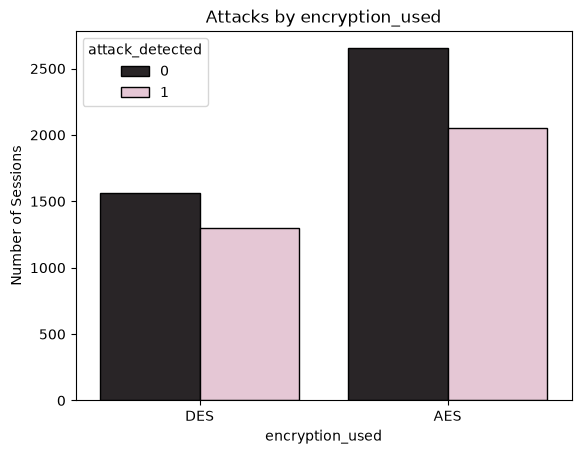

In [62]:
sns.countplot(
    data=cybersecurity_intrusion_data,
    x="encryption_used",
    hue="attack_detected",
    color="#eac2d5e3",edgecolor='black'


)

plt.title("Attacks by encryption_used")
plt.xlabel("encryption_used")
plt.ylabel("Number of Sessions")
plt.show()

In [63]:
cybersecurity_intrusion_data[ 'protocol_type'].value_counts()

protocol_type
TCP     6624
UDP     2406
ICMP     507
Name: count, dtype: int64

In [64]:
mapping = {
    'TCP': 0,
    'UDP': 1,
    'ICMP': 2
}

cybersecurity_intrusion_data['protocol_type'] = cybersecurity_intrusion_data['protocol_type'].map(mapping)

In [65]:
cybersecurity_intrusion_data.head()

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,0,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,0,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,0,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,1,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,0,5,532.540888,AES,0.054874,1,Firefox,0,0


In [66]:
cybersecurity_intrusion_data['encryption_used'].value_counts()

encryption_used
AES    4706
DES    2865
Name: count, dtype: int64

In [67]:

mapping_enc = {'AES': 1, 'DES': 2}
cybersecurity_intrusion_data['encryption_used'] = cybersecurity_intrusion_data['encryption_used'].map(mapping_enc).fillna(0).astype(int)

In [68]:
cybersecurity_intrusion_data['encryption_used'].isna().sum()

np.int64(0)

In [69]:
cybersecurity_intrusion_data['browser_type'].value_counts()

browser_type
Chrome     5137
Firefox    1944
Edge       1469
Unknown     502
Safari      485
Name: count, dtype: int64

In [70]:
browser_type = LabelEncoder()
cybersecurity_intrusion_data['browser_type'] = browser_type.fit_transform(cybersecurity_intrusion_data['browser_type'])

In [71]:
cybersecurity_intrusion_data['browser_type'].value_counts()

browser_type
0    5137
2    1944
1    1469
4     502
3     485
Name: count, dtype: int64

In [72]:
cybersecurity_intrusion_data['failed_ratio'] = (
    cybersecurity_intrusion_data['failed_logins'] / (cybersecurity_intrusion_data['login_attempts'] + 1)
)

In [73]:
cybersecurity_intrusion_data.head()

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected,failed_ratio
0,SID_00001,599,0,4,492.983263,2,0.606818,1,1,0,1,0.200000
1,SID_00002,472,0,3,1557.996461,2,0.301569,0,2,0,0,0.000000
2,SID_00003,629,0,3,75.044262,2,0.739164,2,0,0,1,0.500000
3,SID_00004,804,1,4,601.248835,2,0.123267,0,4,0,1,0.000000
4,SID_00005,453,0,5,532.540888,1,0.054874,1,2,0,0,0.166667


In [74]:
cybersecurity_intrusion_data.isna().sum()

session_id             0
network_packet_size    0
protocol_type          0
login_attempts         0
session_duration       0
encryption_used        0
ip_reputation_score    0
failed_logins          0
browser_type           0
unusual_time_access    0
attack_detected        0
failed_ratio           0
dtype: int64

In [75]:
cybersecurity_intrusion_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   str    
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   int64  
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      9537 non-null   int64  
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   int64  
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
 11  failed_ratio         9537 non-null   float64
dtypes: float64(3), int64(8), str(1)
memory usage: 894.2 KB


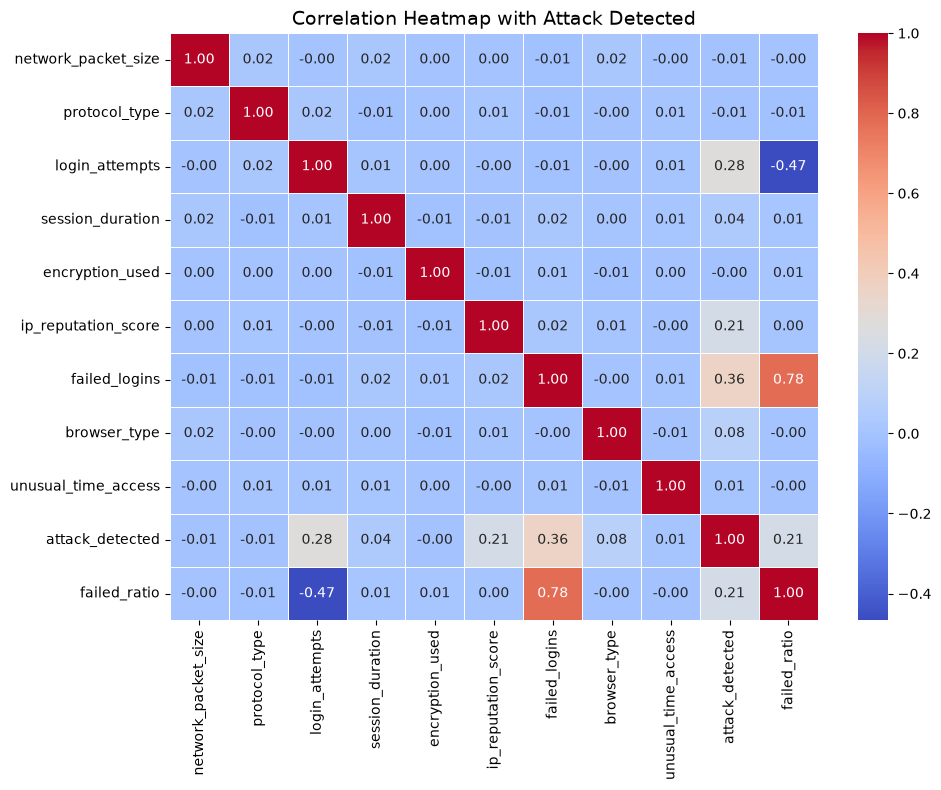

In [76]:

plt.figure(figsize=(10, 8))
corr_matrix = cybersecurity_intrusion_data.drop(columns=['session_id']).corr()


sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap with Attack Detected", fontsize=14)
plt.tight_layout()
plt.show()

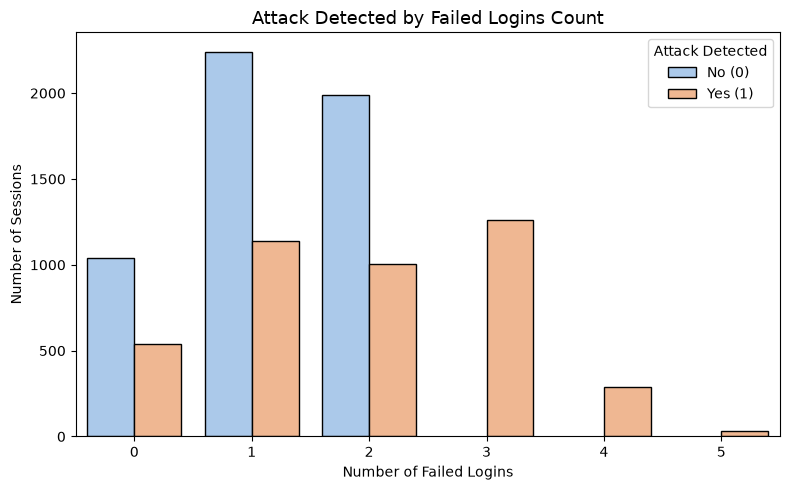

In [77]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=cybersecurity_intrusion_data,
    x="failed_logins",
    hue="attack_detected",
    palette="pastel",
    edgecolor="black"
)

plt.title("Attack Detected by Failed Logins Count", fontsize=13)
plt.xlabel("Number of Failed Logins")
plt.ylabel("Number of Sessions")
plt.legend(title="Attack Detected", labels=["No (0)", "Yes (1)"])
plt.tight_layout()
plt.show()

In [78]:
cybersecurity_intrusion_data_X = cybersecurity_intrusion_data.drop(['session_id', 'attack_detected'], axis=1)
cybersecurity_intrusion_data_Y = cybersecurity_intrusion_data['attack_detected']

In [79]:
cybersecurity_intrusion_data_Y.shape

(9537,)

In [80]:
cybersecurity_intrusion_data_X.shape

(9537, 10)

In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    cybersecurity_intrusion_data_X, cybersecurity_intrusion_data_Y, test_size=0.2, random_state=42, stratify=cybersecurity_intrusion_data_Y
)

## XGBoost Model

In [82]:


xgb_model_cybersecurity = Pipeline(steps=[
    ('classifier', xgb.XGBClassifier(
        objective='binary:logistic',
        n_estimators=450,
        learning_rate=0.03,         
        max_depth=6,                  
        subsample=0.85,               
        colsample_bytree=0.85,        
        min_child_weight=3,          
        gamma=0.1,                    
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

In [83]:
xgb_model_cybersecurity.fit(X_train, y_train)
y_pred_xgb = xgb_model_cybersecurity.predict(X_test)

In [84]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"Accuracy: {accuracy_xgb * 100:.2f}%\n")

Accuracy: 88.68%



In [85]:
auc = roc_auc_score(y_test, y_pred_xgb)
print(f"ROC-AUC Score: {auc * 100:.2f}%\n")

ROC-AUC Score: 87.35%



In [86]:
print("Classification Report:")
classification_report(y_test, y_pred_xgb, target_names=['Normal (0)', 'Attack (1)'])

Classification Report:


'              precision    recall  f1-score   support\n\n  Normal (0)       0.83      1.00      0.91      1055\n  Attack (1)       1.00      0.75      0.86       853\n\n    accuracy                           0.89      1908\n   macro avg       0.91      0.87      0.88      1908\nweighted avg       0.91      0.89      0.88      1908\n'

In [87]:
feature_importance = xgb_model_cybersecurity.named_steps['classifier'].feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)


print("=" * 45)
print(" ترتيب أهمية الميزات في اكتشاف الهجوم:")
print("=" * 45)
display(feature_importance_df)

 ترتيب أهمية الميزات في اكتشاف الهجوم:


,Feature,Importance
0,failed_logins,0.477146
1,login_attempts,0.238437
2,ip_reputation_score,0.073123
3,failed_ratio,0.057269
4,browser_type,0.056810
5,unusual_time_access,0.035970
6,session_duration,0.016950
7,network_packet_size,0.015415
8,protocol_type,0.014754
9,encryption_used,0.014126


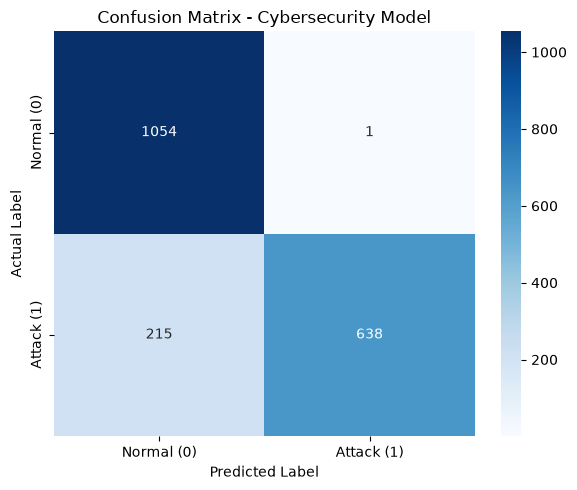

In [88]:
conf_mat = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Attack (1)'],
            yticklabels=['Normal (0)', 'Attack (1)'])
plt.title('Confusion Matrix - Cybersecurity Model')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

RandomizedSearchCV

In [89]:

param_dist = {
    'classifier__n_estimators': [250, 350, 500,5000],
    'classifier__learning_rate': [0.02, 0.04, 0.06, 0.08],
    'classifier__max_depth': [5, 6, 7, 8],
    'classifier__min_child_weight': [1, 3, 5],
    'classifier__subsample': [0.75, 0.85, 0.95],
    'classifier__colsample_bytree': [0.75, 0.85, 0.95],
    'classifier__gamma': [0, 0.1, 0.2]
}


base_pipeline = Pipeline(steps=[
    ('classifier', xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

random_search = RandomizedSearchCV(
    estimator=base_pipeline,
    param_distributions=param_dist,
    n_iter=15,                  
    scoring='accuracy',
    cv=3,                       
    verbose=1,
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train, y_train)


best_xgb = random_search.best_estimator_
y_pred_best = best_xgb.predict(X_test)

print("=" * 45)
print(f" أفضل دقة تحققت: {accuracy_score(y_test, y_pred_best) * 100:.2f}%")
print("أفضل المعاملات الفائقة:")
print(random_search.best_params_)
print("=" * 45)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
 أفضل دقة تحققت: 88.63%
أفضل المعاملات الفائقة:
{'classifier__subsample': 0.75, 'classifier__n_estimators': 350, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.02, 'classifier__gamma': 0.2, 'classifier__colsample_bytree': 0.85}


LightGBM

In [90]:
lgbm_model_cybersecurity = LGBMClassifier(
    objective='binary',            
    n_estimators=300,             
    learning_rate=0.03,           
    num_leaves=31,                
    max_depth=6,                   
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1                     
)


lgbm_model_cybersecurity.fit(X_train, y_train)


y_pred_lgbm = lgbm_model_cybersecurity.predict(X_test)
y_proba_lgbm = lgbm_model_cybersecurity.predict_proba(X_test)[:, 1]

In [91]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_lgbm) * 100:.2f}%")

Accuracy: 88.68%


Logistic Regression

In [92]:
from sklearn.preprocessing import StandardScaler

logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()), # ضروري جداً لضبط مقاييس الأرقام
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

logistic_pipeline.fit(X_train, y_train)
y_pred_log = logistic_pipeline.predict(X_test)

print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_log) * 100:.2f}%")

Logistic Regression Accuracy: 74.53%


Random Forest

In [93]:

rf_model_cybersecurity = Pipeline(steps=[
    ('classifier', RandomForestClassifier(
        n_estimators=300,        
        max_depth=12,             
        min_samples_split=5,       
        min_samples_leaf=2,       
        max_features='sqrt',       
        criterion='gini',          
        random_state=42,
        n_jobs=-1                  
    ))
])


rf_model_cybersecurity.fit(X_train, y_train)


y_pred_rf = rf_model_cybersecurity.predict(X_test)


acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Accuracy: {acc_rf * 100:.2f}%")


Accuracy: 88.63%


In [94]:

models_comparison = {
    'XGBoost': accuracy_score(y_test, y_pred_xgb),
    'RandomizedSearchCV': accuracy_score(y_test, y_pred_best),
    'LightGBM': accuracy_score(y_test, y_pred_lgbm),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
    'Logistic Regression': accuracy_score(y_test, y_pred_log)
}


df_models = pd.DataFrame(list(models_comparison.items()), columns=['Model', 'Accuracy'])
df_models['Accuracy (%)'] = (df_models['Accuracy'] * 100).round(2)
df_models = df_models.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)


display(df_models[['Model', 'Accuracy (%)']])


,Model,Accuracy (%)
0,XGBoost,88.68
1,LightGBM,88.68
2,RandomizedSearchCV,88.63
3,Random Forest,88.63
4,Logistic Regression,74.53


In [95]:
joblib.dump(xgb_model_cybersecurity, "cybersecurity_model.pkl")

['cybersecurity_model.pkl']

In [96]:
print(xgb_model_cybersecurity.feature_names_in_)

['network_packet_size' 'protocol_type' 'login_attempts' 'session_duration'
 'encryption_used' 'ip_reputation_score' 'failed_logins' 'browser_type'
 'unusual_time_access' 'failed_ratio']


In [1]:


# 1. تحميل النموذج
model = joblib.load("cybersecurity_model.pkl")
print("✅ Model loaded successfully!\n")

# 2. القواميس الشاملة لكل النصوص (البروتوكول، التشفير، المتصفح)
protocol_mapping = {'TCP': 0, 'UDP': 1, 'ICMP': 2}
encryption_mapping = {'NONE': 0, 'AES': 1, 'DES': 2}
browser_mapping = {
    'CHROME': 0,
    'EDGE': 1,
    'FIREFOX': 2,
    'SAFARI': 3,
    'UNKNOWN': 4
}

print("--- Enter Network Session Details ---")

# إدخال البيانات الرقمية
network_packet_size = float(input("Network Packet Size: "))
session_duration = float(input("Session Duration (seconds): "))
login_attempts = float(input("Login Attempts: "))
failed_logins = float(input("Failed Logins: "))
ip_reputation_score = float(input("IP Reputation Score (0.0 to 1.0): "))
unusual_time_access = int(input("Unusual Time Access (0 = No, 1 = Yes): "))

# 3. إدخال وتحويل Protocol Type
print("\nProtocol Options: TCP, UDP, ICMP")
proto_input = input("Choose Protocol: ").strip().upper()
protocol_type = protocol_mapping.get(proto_input, 0)

# 4. إدخال وتحويل Encryption Used
print("\nEncryption Options: NONE, AES, DES")
enc_input = input("Choose Encryption: ").strip().upper()
encryption_used = encryption_mapping.get(enc_input, 0)

# 5. إدخال وتحويل Browser Type (بالقاموس مباشرة دون الحاجة لـ LabelEncoder)
print("\nBrowser Options: Chrome, Edge, Firefox, Safari, Unknown")
browser_input = input("Choose Browser: ").strip().upper()
browser_type_encoded = browser_mapping.get(browser_input, 4)

# 6. تجميع البيانات
session_data = pd.DataFrame([{
    'network_packet_size': network_packet_size,
    'protocol_type': protocol_type,
    'login_attempts': login_attempts,
    'session_duration': session_duration,
    'encryption_used': encryption_used,
    'ip_reputation_score': ip_reputation_score,
    'failed_logins': failed_logins,
    'browser_type': browser_type_encoded,
    'unusual_time_access': unusual_time_access
}])

if 'failed_ratio' in X_train.columns:
    session_data['failed_ratio'] = failed_logins / (login_attempts + 1)

session_data = session_data[X_train.columns]


prediction = model.predict(session_data)[0]
probability = model.predict_proba(session_data)[0][1] * 100

print("\n" + "=" * 45)
print(" Cybersecurity Intrusion Detection Result:")
print("=" * 45)
if prediction == 1:
    print(f" ALERT: Attack Detected! (محاولة اختراق)")
else:
    print(f" SAFE: Normal Session (جلسة طبيعية آمنة)")

print(f" Attack Risk Probability: {probability:.2f}%")
print("=" * 45)

NameError: name 'joblib' is not defined